<a href="https://colab.research.google.com/github/enuriherath-blip/Cat_Dog_Classifier/blob/main/cat_dog_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install numpy -q
!pip install pandas -q
!pip install matplotlib -q
!pip install tensorflow -q
!pip install opendatasets -q

In [5]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import time
import opendatasets as od

In [6]:
od.download("https://www.kaggle.com/datasets/dineshpiyasamara/cats-and-dogs-for-classification")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: enuriherath
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/dineshpiyasamara/cats-and-dogs-for-classification


100%|██████████| 217M/217M [00:01<00:00, 135MB/s]


In [7]:
BATCH_SIZE = 32
IMAGE_SIZE = (128,128)

In [8]:
train_data_dir = "/content/cats-and-dogs-for-classification/cats_dogs/train"
test_data_dir = "/content/cats-and-dogs-for-classification/cats_dogs/test"

In [9]:
train_data = tf.keras.utils.image_dataset_from_directory(train_data_dir,
                                                         batch_size=BATCH_SIZE,
                                                         image_size=IMAGE_SIZE,
                                                         subset='training',
                                                         validation_split=0.1,
                                                         seed=42)

validation_data = tf.keras.utils.image_dataset_from_directory(train_data_dir,
                                                         batch_size=BATCH_SIZE,
                                                         image_size=IMAGE_SIZE,
                                                         subset='validation',
                                                         validation_split=0.1,
                                                         seed=42)

test_data = tf.keras.utils.image_dataset_from_directory(test_data_dir,
                                                         batch_size=BATCH_SIZE,
                                                         image_size=IMAGE_SIZE)

Found 8000 files belonging to 2 classes.
Using 7200 files for training.
Found 8000 files belonging to 2 classes.
Using 800 files for validation.
Found 2000 files belonging to 2 classes.


In [10]:
class_names = train_data.class_names
class_names

['cats', 'dogs']

In [11]:
for image_batch, label_batch in train_data.take(1):
  print(image_batch.shape)
  print(label_batch.shape)

(32, 128, 128, 3)
(32,)


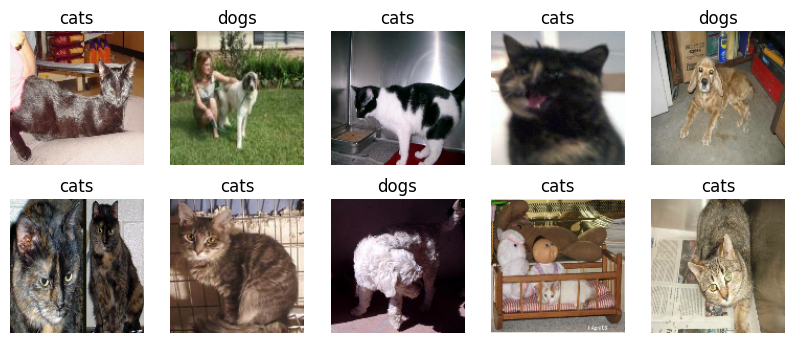

In [12]:
# plot data sample
plt.figure(figsize=(10,4))
for image,label in train_data.take(1):
    for i in range(10):
        ax = plt.subplot(2,5,i+1)
        plt.imshow(image[i].numpy().astype('uint8'))
        plt.title(class_names[label[i]])
        plt.axis('off')

Scaling Images

In [13]:
for image,label in train_data.take(1):
    for i in range(1):
      print(image)


tf.Tensor(
[[[[101.00769   104.00769   109.00769  ]
   [111.074585  112.71521   114.30505  ]
   [117.635284  115.31354   112.59396  ]
   ...
   [129.86246   132.91324   136.22964  ]
   [126.8725    133.10297   135.69281  ]
   [128.9002    138.99207   139.94614  ]]

  [[ 85.20029    88.20029    93.20029  ]
   [ 99.3725     99.79227   101.78906  ]
   [114.00287   112.997925  110.048706 ]
   ...
   [116.720825  120.720825  123.720825 ]
   [119.9389    126.16937   128.75922  ]
   [138.79547   147.0824    148.93893  ]]

  [[ 92.54297    94.90234    99.58203  ]
   [ 91.57605    91.986206   93.986206 ]
   [105.38388   104.38388   101.75107  ]
   ...
   [120.73743   125.52237   128.52237  ]
   [130.21445   135.21445   138.21445  ]
   [127.32648   134.36554   136.68585  ]]

  ...

  [[118.07504   122.07504   125.07504  ]
   [121.617584  125.617584  128.61758  ]
   [130.54602   134.54602   137.54602  ]
   ...
   [ 81.51825    87.02301    96.76108  ]
   [ 45.951294   50.819916   54.147003 ]
   [ 

In [14]:
train_data = train_data.map(lambda x,y:(x/255,y))
validation_data = validation_data.map(lambda x,y:(x/255,y))
test_data = test_data.map(lambda x,y:(x/255,y))

In [15]:
for image,label in train_data.take(1):
    for i in range(1):
      print(image)

tf.Tensor(
[[[[0.15117954 0.08451287 0.12372855]
   [0.1564951  0.08982843 0.12904412]
   [0.14387254 0.07720588 0.11642157]
   ...
   [0.         0.00392157 0.        ]
   [0.         0.         0.        ]
   [0.         0.         0.        ]]

  [[0.15078124 0.08411458 0.12333027]
   [0.1463848  0.07971814 0.11893383]
   [0.13852635 0.07185968 0.11107536]
   ...
   [0.         0.         0.        ]
   [0.         0.00127145 0.        ]
   [0.         0.         0.        ]]

  [[0.15681386 0.09014719 0.12936288]
   [0.15010071 0.08343404 0.12264973]
   [0.1491728  0.08250613 0.12172181]
   ...
   [0.00392157 0.         0.        ]
   [0.         0.00392157 0.        ]
   [0.         0.         0.        ]]

  ...

  [[0.7237403  0.6738876  0.726761  ]
   [0.7528033  0.7035823  0.75956535]
   [0.77319306 0.71951526 0.7698836 ]
   ...
   [0.04705882 0.00392157 0.03529412]
   [0.05098039 0.         0.03529412]
   [0.0395804  0.         0.03137255]]

  [[0.7596398  0.66668636 0.694030

Data Augmentation

In [16]:
data_augmentation = tf.keras.Sequential(
  [
    tf.keras.layers.RandomFlip("horizontal",input_shape=(128,128,3)),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
  ]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model Building

In [17]:
model = tf.keras.models.Sequential()

model.add(data_augmentation)

model.add(tf.keras.layers.Conv2D(32, kernel_size=3, activation='relu'))
model.add(tf.keras.layers.MaxPooling2D())

model.add(tf.keras.layers.Conv2D(64, kernel_size=3, activation='relu'))
model.add(tf.keras.layers.MaxPooling2D())

model.add(tf.keras.layers.Conv2D(128, kernel_size=3, activation='relu'))
model.add(tf.keras.layers.MaxPooling2D())

model.add(tf.keras.layers.Dropout(0.2))
model.add(tf.keras.layers.BatchNormalization())

model.add(tf.keras.layers.Flatten())

model.add(tf.keras.layers.Dense(128, activation='relu'))
model.add(tf.keras.layers.Dense(128, activation='relu'))
model.add(tf.keras.layers.Dense(32, activation='relu'))

model.add(tf.keras.layers.Dense(1, activation='sigmoid'))

In [18]:
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,325,825 (12.69 MB)

 Trainable params: 3,325,569 (12.69 MB)

 Non-trainable params: 256 (1.00 KB)

In [19]:
model.compile(optimizer=tf.keras.optimizers.Adam(),
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=['accuracy'])

model Trainning

In [20]:
start_time = time.time()

history = model.fit(train_data,
                    epochs=20,
                    validation_data=validation_data)

end_time = time.time()

Epoch 1/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.5907 - loss: 0.6673 - val_accuracy: 0.6050 - val_loss: 0.6601
Epoch 2/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.6443 - loss: 0.6302 - val_accuracy: 0.6725 - val_loss: 0.6035
Epoch 3/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/step - accuracy: 0.6575 - loss: 0.6113 - val_accuracy: 0.5213 - val_loss: 1.2114
Epoch 4/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - accuracy: 0.6589 - loss: 0.6105 - val_accuracy: 0.5850 - val_loss: 0.6568
Epoch 5/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.6857 - loss: 0.5881 - val_accuracy: 0.6925 - val_loss: 0.6085
Epoch 6/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.6944 - loss: 0.5817 - val_accuracy: 0.6600 - val_loss: 0.5979
Epoch 7/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - accuracy: 0.6953 - loss: 0.5719 - val_accuracy: 0.6550 - val_loss: 0.6134
Epoch 8/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.7151 - loss: 0.5590 - val_ac

In [21]:
history.history

{'accuracy': [0.5906944274902344,
  0.6443055272102356,
  0.6575000286102295,
  0.6588888764381409,
  0.6856944561004639,
  0.6944444179534912,
  0.695277750492096,
  0.7151389122009277,
  0.714722216129303,
  0.7376388907432556,
  0.7406944632530212,
  0.7456944584846497,
  0.758055567741394,
  0.762499988079071,
  0.7629166841506958,
  0.7652778029441833,
  0.7756944298744202,
  0.7802777886390686,
  0.7838888764381409,
  0.7868055701255798],
 'loss': [0.6673316359519958,
  0.6302139163017273,
  0.611315906047821,
  0.6104578971862793,
  0.5880763530731201,
  0.5816614031791687,
  0.5718663930892944,
  0.5590366721153259,
  0.5479196310043335,
  0.5277047157287598,
  0.5190817713737488,
  0.5093962550163269,
  0.49096807837486267,
  0.489841490983963,
  0.4845178425312042,
  0.47451213002204895,
  0.4666327238082886,
  0.4577826261520386,
  0.4542633295059204,
  0.4521179795265198],
 'val_accuracy': [0.6050000190734863,
  0.6725000143051147,
  0.5212500095367432,
  0.5849999785423279

Performance Analysis

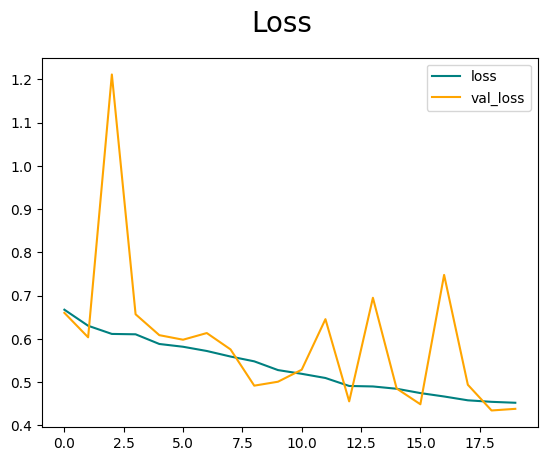

In [22]:
fig = plt.figure()
plt.plot(history.history['loss'], color='teal', label='loss')
plt.plot(history.history['val_loss'], color='orange', label='val_loss')
fig.suptitle('Loss', fontsize=20)
plt.legend()
plt.show()

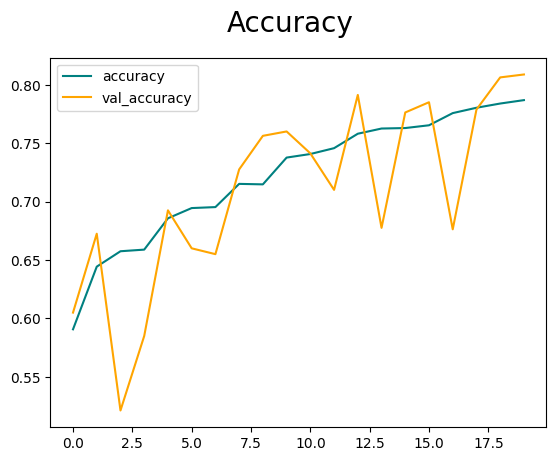

In [23]:
fig = plt.figure()
plt.plot(history.history['accuracy'], color='teal', label='accuracy')
plt.plot(history.history['val_accuracy'], color='orange', label='val_accuracy')
fig.suptitle('Accuracy', fontsize=20)
plt.legend()
plt.show()

Model Evaluation

In [24]:
precision = tf.keras.metrics.Precision()
recall = tf.keras.metrics.Recall()
accuracy = tf.keras.metrics.BinaryAccuracy()

In [25]:
for batch in test_data.as_numpy_iterator():
    X, y = batch
    yhat = model.predict(X)
    precision.update_state(y, yhat)
    recall.update_state(y, yhat)
    accuracy.update_state(y, yhat)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━

In [26]:
precision.result()

<tf.Tensor: shape=(), dtype=float32, numpy=0.7884796857833862>

In [27]:
recall.result()

<tf.Tensor: shape=(), dtype=float32, numpy=0.8349999785423279>

In [28]:
accuracy.result()

<tf.Tensor: shape=(), dtype=float32, numpy=0.8054999709129333>

In [29]:
!pip install opencv-Python

In [30]:
import cv2

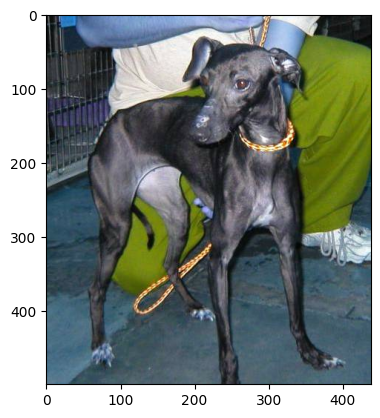

In [31]:
image = cv2.imread("/content/cats-and-dogs-for-classification/cats_dogs/test/dogs/dog.4004.jpg")
plt.imshow(image)
plt.show()


In [32]:
resized_image = tf.image.resize(image, IMAGE_SIZE)
scaled_image = resized_image/255

In [33]:
scaled_image

<tf.Tensor: shape=(128, 128, 3), dtype=float32, numpy=
array([[[0.10454868, 0.12239487, 0.12972508],
        [0.08293708, 0.10254493, 0.10294321],
        [0.06077785, 0.07662617, 0.09083946],
        ...,
        [0.11517633, 0.12301947, 0.12694104],
        [0.11508885, 0.12293199, 0.12293199],
        [0.1084712 , 0.11631434, 0.11631434]],

       [[0.13378164, 0.13460885, 0.13295443],
        [0.14583454, 0.1497561 , 0.13918625],
        [0.04644811, 0.05022978, 0.04008885],
        ...,
        [0.11233353, 0.12017667, 0.12409823],
        [0.07681251, 0.08465564, 0.08465564],
        [0.08437153, 0.09221467, 0.09221467]],

       [[0.07784244, 0.09207787, 0.09965617],
        [0.16114071, 0.17774814, 0.17374998],
        [0.04631156, 0.06323015, 0.0469498 ],
        ...,
        [0.08509497, 0.09293811, 0.09685968],
        [0.0755188 , 0.08336194, 0.08336194],
        [0.08400735, 0.09185049, 0.09185049]],

       ...,

       [[0.3322961 , 0.469551  , 0.5479824 ],
        [0.33

In [34]:
np.expand_dims(scaled_image, 0).shape

(1, 128, 128, 3)

In [35]:
yhat = model.predict(np.expand_dims(scaled_image, 0))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step


In [36]:
yhat

array([[0.9673692]], dtype=float32)

In [37]:
if yhat > 0.5:
    print(f'{class_names[1]}')
else:
    print(f'{class_names[0]}')


dogs


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


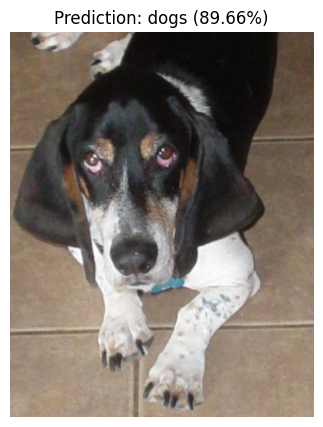

In [39]:
def predict_image(image_path):
    # Load image using OpenCV
    img = cv2.imread(image_path)
    if img is None:
        print("Error: Image not found.")
        return

    # OpenCV loads images in BGR, convert to RGB for displaying correctly
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Preprocess image to match training parameters
    resized_img = tf.image.resize(img_rgb, IMAGE_SIZE)
    scaled_img = resized_img / 255.0

    # Model prediction
    prediction = model.predict(np.expand_dims(scaled_img, 0))[0][0]

    # Determine predicted class and confidence
    if prediction > 0.5:
        label = class_names[1]
        confidence = prediction * 100
    else:
        label = class_names[0]
        confidence = (1 - prediction) * 100

    # Plot the image and prediction
    plt.figure(figsize=(5, 5))
    plt.imshow(img_rgb)
    plt.title(f"Prediction: {label} ({confidence:.2f}%)")
    plt.axis('off')
    plt.show()

# Example usage with your test dog image:
test_img_path = "/content/cats-and-dogs-for-classification/cats_dogs/test/dogs/dog.4128.jpg"
predict_image(test_img_path)

Transfer learning Model

In [40]:
# 1. Load the pre-trained MobileNetV2 model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights='imagenet'
)

# 2. Freeze the base model to retain pre-trained weights
base_model.trainable = False

# 3. Build the transfer learning architecture
transfer_model = tf.keras.models.Sequential([
    data_augmentation,
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

transfer_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [41]:
# 4. Compile the transfer learning model
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

In [42]:
# 5. Train the transfer learning model
transfer_history = transfer_model.fit(
    train_data,
    epochs=10,
    validation_data=validation_data
)

Epoch 1/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.8397 - loss: 0.3414 - val_accuracy: 0.9638 - val_loss: 0.0946
Epoch 2/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - accuracy: 0.8910 - loss: 0.2486 - val_accuracy: 0.9712 - val_loss: 0.0833
Epoch 3/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - accuracy: 0.8960 - loss: 0.2327 - val_accuracy: 0.9663 - val_loss: 0.0823
Epoch 4/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - accuracy: 0.9090 - loss: 0.2158 - val_accuracy: 0.9688 - val_loss: 0.0777
Epoch 5/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.9026 - loss: 0.2287 - val_accuracy: 0.9675 - val_loss: 0.0794
Epoch 6/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - accuracy: 0.9015 - loss: 0.2288 - val_accuracy: 0.9700 - val_loss: 0.0795
Epoch 7/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.9092 - loss: 0.2132 - val_accuracy: 0.9688 - val_loss: 0.0756
Epoch 8/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/step - accuracy: 0.9121 - loss: 0.2066 - val_a

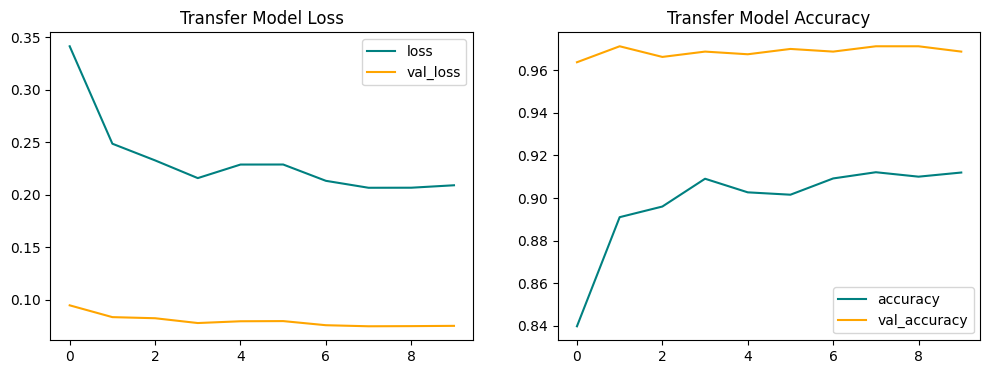

In [43]:
# 6. Plot Training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Loss
ax1.plot(transfer_history.history['loss'], color='teal', label='loss')
ax1.plot(transfer_history.history['val_loss'], color='orange', label='val_loss')
ax1.set_title('Transfer Model Loss')
ax1.legend()

# Accuracy
ax2.plot(transfer_history.history['accuracy'], color='teal', label='accuracy')
ax2.plot(transfer_history.history['val_accuracy'], color='orange', label='val_accuracy')
ax2.set_title('Transfer Model Accuracy')
ax2.legend()

plt.show()

Model Evaluvation

In [44]:
# Initialize evaluation metrics for the transfer model
transfer_precision = tf.keras.metrics.Precision()
transfer_recall = tf.keras.metrics.Recall()
transfer_accuracy = tf.keras.metrics.BinaryAccuracy()

# Run prediction loop over test data
for batch in test_data.as_numpy_iterator():
    X_batch, y_batch = batch
    predictions = transfer_model.predict(X_batch, verbose=0)
    transfer_precision.update_state(y_batch, predictions)
    transfer_recall.update_state(y_batch, predictions)
    transfer_accuracy.update_state(y_batch, predictions)

print(f"Transfer Model Test Accuracy: {transfer_accuracy.result().numpy():.4f}")
print(f"Transfer Model Test Precision: {transfer_precision.result().numpy():.4f}")
print(f"Transfer Model Test Recall: {transfer_recall.result().numpy():.4f}")

Transfer Model Test Accuracy: 0.9690
Transfer Model Test Precision: 0.9718
Transfer Model Test Recall: 0.9660


Updating the Prediction Function

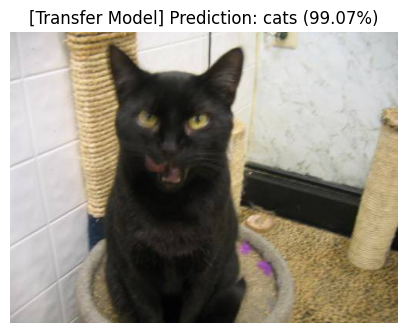

In [45]:
def predict_image_v2(image_path):
    # Load image using OpenCV
    img = cv2.imread(image_path)
    if img is None:
        print("Error: Image not found.")
        return

    # Convert BGR to RGB
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Resize and scale
    resized_img = tf.image.resize(img_rgb, IMAGE_SIZE)
    scaled_img = resized_img / 255.0

    # Predict using the newly trained transfer_model
    prediction = transfer_model.predict(np.expand_dims(scaled_img, 0), verbose=0)[0][0]

    # Class mapping
    if prediction > 0.5:
        label = class_names[1]
        confidence = prediction * 100
    else:
        label = class_names[0]
        confidence = (1 - prediction) * 100

    # Plot image and predictions
    plt.figure(figsize=(5, 5))
    plt.imshow(img_rgb)
    plt.title(f"[Transfer Model] Prediction: {label} ({confidence:.2f}%)")
    plt.axis('off')
    plt.show()

# Test it on a sample dog image
predict_image_v2("/content/cats-and-dogs-for-classification/cats_dogs/test/cats/cat.4024.jpg")